In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from typing import Tuple

# Load dataset

In [3]:
df = pd.read_parquet("../data/cisto.parquet")

# Histograms

## Total price

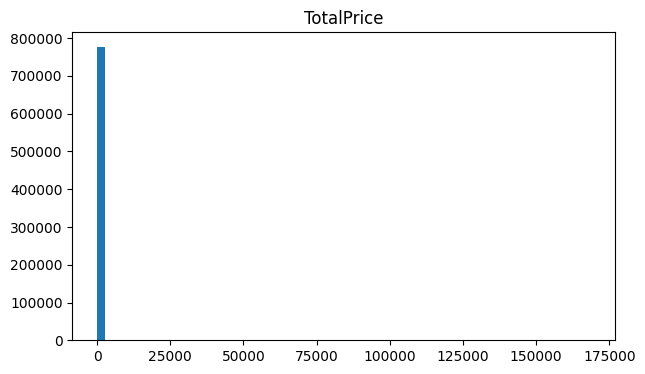

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df.TotalPrice, bins=60)
ax.set_title("TotalPrice")
plt.show()

## Total price log

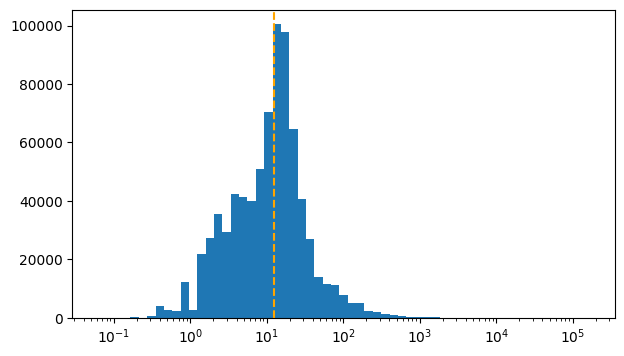

In [7]:
positive = df.TotalPrice[df.TotalPrice > 0]
bins = np.logspace(np.log10(positive.min()), np.log10(positive.max()), 60)

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(positive, bins=bins)
ax.set_xscale("log")
ax.axvline(df.TotalPrice.median(), color="orange", linestyle="--")
plt.show()

## Quantity

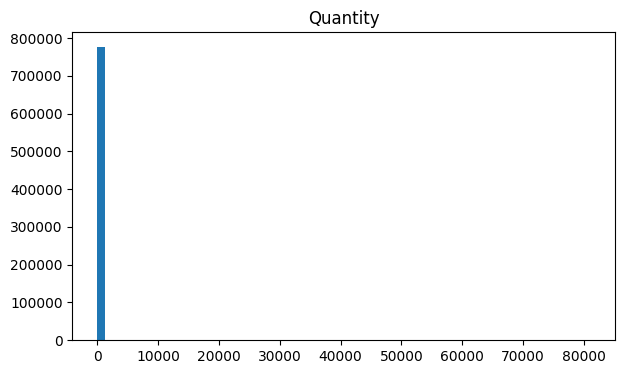

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df.Quantity, bins=60)
ax.set_title("Quantity")
plt.show()

## Quantity log

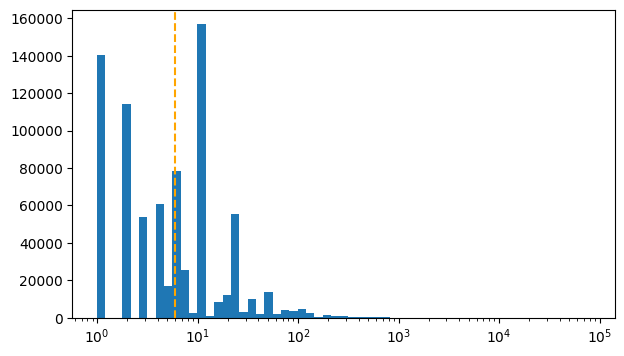

In [9]:
positive = df.Quantity[df.Quantity > 0]
bins = np.logspace(np.log10(positive.min()), np.log10(positive.max()), 60)

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(positive, bins=bins)
ax.set_xscale("log")
ax.axvline(df.Quantity.median(), color="orange", linestyle="--")
plt.show()

## UnitPrice

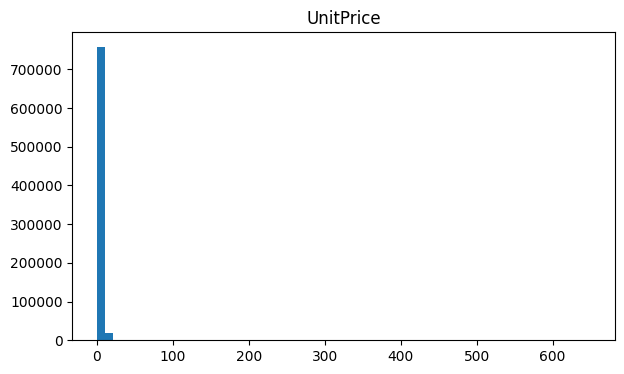

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df.UnitPrice, bins=60)
ax.set_title("UnitPrice")
plt.show()

## UnitPrice log

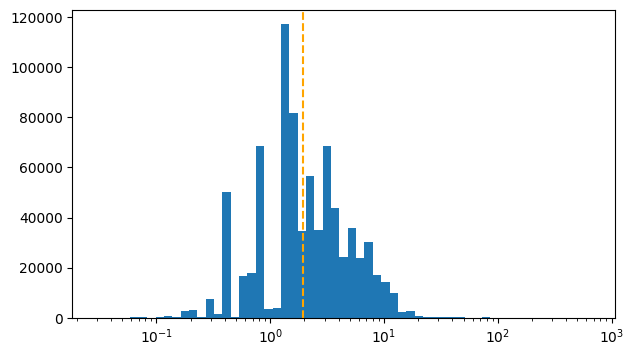

In [11]:
positive = df.UnitPrice[df.UnitPrice > 0]
bins = np.logspace(np.log10(positive.min()), np.log10(positive.max()), 60)

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(positive, bins=bins)
ax.set_xscale("log")
ax.axvline(df.UnitPrice.median(), color="orange", linestyle="--")
plt.show()

## Outliers

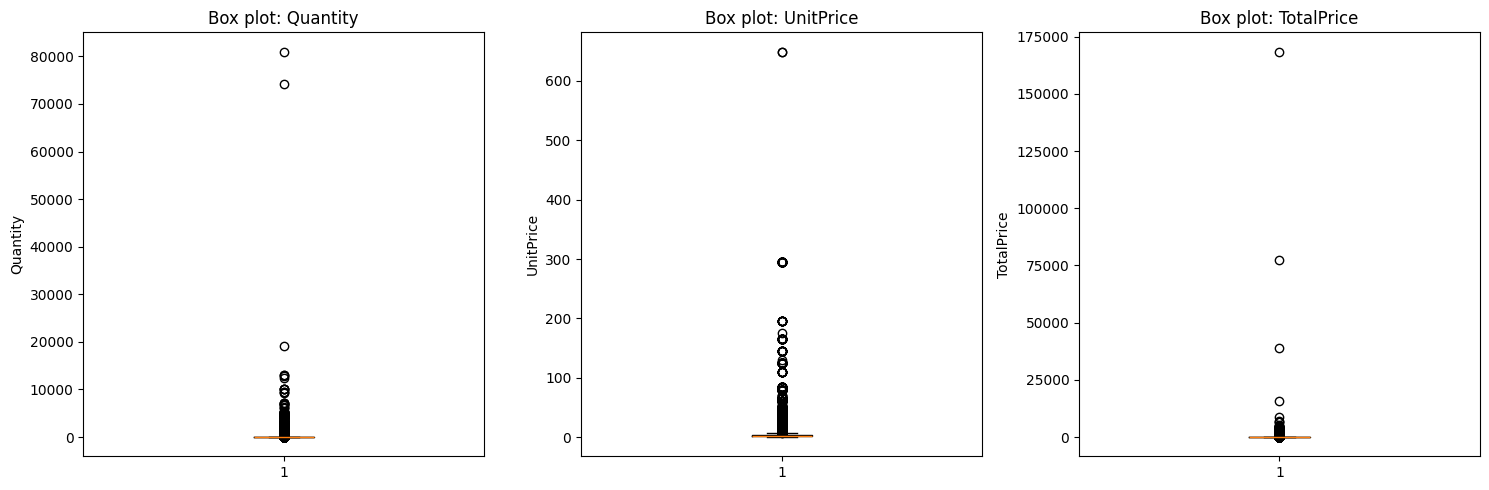

In [18]:
cols = ["Quantity", "UnitPrice", "TotalPrice"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col in zip(axes, cols):
    ax.boxplot(df[col].dropna(), vert=True)
    ax.set_title(f'Box plot: {col}')
    ax.set_ylabel(col)
plt.tight_layout()
plt.show()

In [20]:
def iqr_outliers(series: pd.Series):
    s = series.dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (s < lower) | (s > upper)
    return lower, upper, mask.sum(), mask.mean() * 100

results = []
for col in cols:
    lower, upper, n_out, pct = iqr_outliers(df[col])
    results.append({
        'kolona': col,
        'donja_granica': lower,
        'gornja_granica': upper,
        'broj_outliera': n_out,
        'procenat': f"{round(pct, 2)}%"
    })

print(pd.DataFrame(results))

       kolona  donja_granica  gornja_granica  broj_outliera procenat
0    Quantity        -13.000          27.000          51077    6.58%
1   UnitPrice         -2.500           7.500          63131    8.13%
2  TotalPrice        -17.325          42.075          62197    8.01%


## Quantity, UnitPirce, TotalPrice mean median

In [15]:
def get_mean_median(column: str) -> Tuple[float, float]:
    return round(df[column].mean(), 2), round(df[column].median(), 2)

quantity_mean, quantity_median = get_mean_median("Quantity")
unitprice_mean, unitprice_median = get_mean_median("UnitPrice")
totalprice_mean, totalprice_median = get_mean_median("TotalPrice")

print(f"Quantity mean: {quantity_mean}")
print(f"Quantity median: {quantity_median}")

print(f"UnitPrice mean: {unitprice_mean}")
print(f"UnitPrice median: {unitprice_median}")

print(f"TotalPrice mean: {totalprice_mean}")
print(f"TotalPrice median: {totalprice_median}")

Quantity mean: 13.52
Quantity median: 6.0
UnitPrice mean: 2.93
UnitPrice median: 1.95
TotalPrice mean: 21.98
TotalPrice median: 12.45


# TotalPrice 10 largest

In [16]:
df.nlargest(10, "TotalPrice")

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,List,TotalPrice,Godina,Mesec,Datum,DanUNedelji,Sat
776118,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446,United Kingdom,Year 2010-2011,168469.60,2011,2011-12,2011-12-09,4,9
421804,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346,United Kingdom,Year 2010-2011,77183.60,2011,2011-01,2011-01-18,1,10
538378,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,2011-06-10 15:28:00,649.50,15098,United Kingdom,Year 2010-2011,38970.00,2011,2011-06,2011-06-10,4,15
332011,530715,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,2010-11-04 11:36:00,1.69,15838,United Kingdom,Year 2009-2010,15818.40,2010,2010-11,2010-11-04,3,11
169271,511465,15044A,PINK PAPER PARASOL,3500,2010-06-08 12:59:00,2.55,18008,United Kingdom,Year 2009-2010,8925.00,2010,2010-06,2010-06-08,1,12
630484,567423,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,2011-09-20 11:05:00,5.06,17450,United Kingdom,Year 2010-2011,7144.72,2011,2011-09,2011-09-20,1,11
417500,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2011-01-11 12:55:00,2.10,15749,United Kingdom,Year 2010-2011,6539.40,2011,2011-01,2011-01-11,1,12
493189,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2011-04-18 13:20:00,2.10,15749,United Kingdom,Year 2010-2011,6539.40,2011,2011-04,2011-04-18,0,13
289757,525968,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,3120,2010-10-08 10:10:00,1.66,15838,United Kingdom,Year 2009-2010,5179.20,2010,2010-10,2010-10-08,4,10
688829,573003,23084,RABBIT NIGHT LIGHT,2400,2011-10-27 12:11:00,2.08,14646,Netherlands,Year 2010-2011,4992.00,2011,2011-10,2011-10-27,3,12


# By Countries

In [23]:
by_countries = (df.groupby("Country")
                .agg(Prihod=("TotalPrice", "sum"),
                     Kupaca=("CustomerID", "nunique"),
                     Racuna=("InvoiceNo", "nunique"))
                .sort_values("Prihod", ascending=False))

by_countries["Udeo %"] = by_countries.Prihod / by_countries.Prihod.sum() * 100
by_countries["ProsecnaKorpa"] = by_countries.Prihod / by_countries.Racuna
by_countries


,Prihod,Kupaca,Racuna,Udeo %,ProsecnaKorpa
Country,,,,,
United Kingdom,14288773.50,5334,33361,83.713884,428.307710
EIRE,586626.08,3,528,3.436876,1111.034242
Netherlands,549773.41,22,216,3.220967,2545.247269
Germany,383289.00,107,753,2.245582,509.015936
France,309403.16,93,590,1.812706,524.412136
Australia,167800.01,15,89,0.983093,1885.393371
Spain,97766.75,38,144,0.572788,678.935764
Switzerland,93400.94,22,82,0.547210,1139.035854
Sweden,86045.14,19,98,0.504114,878.011633


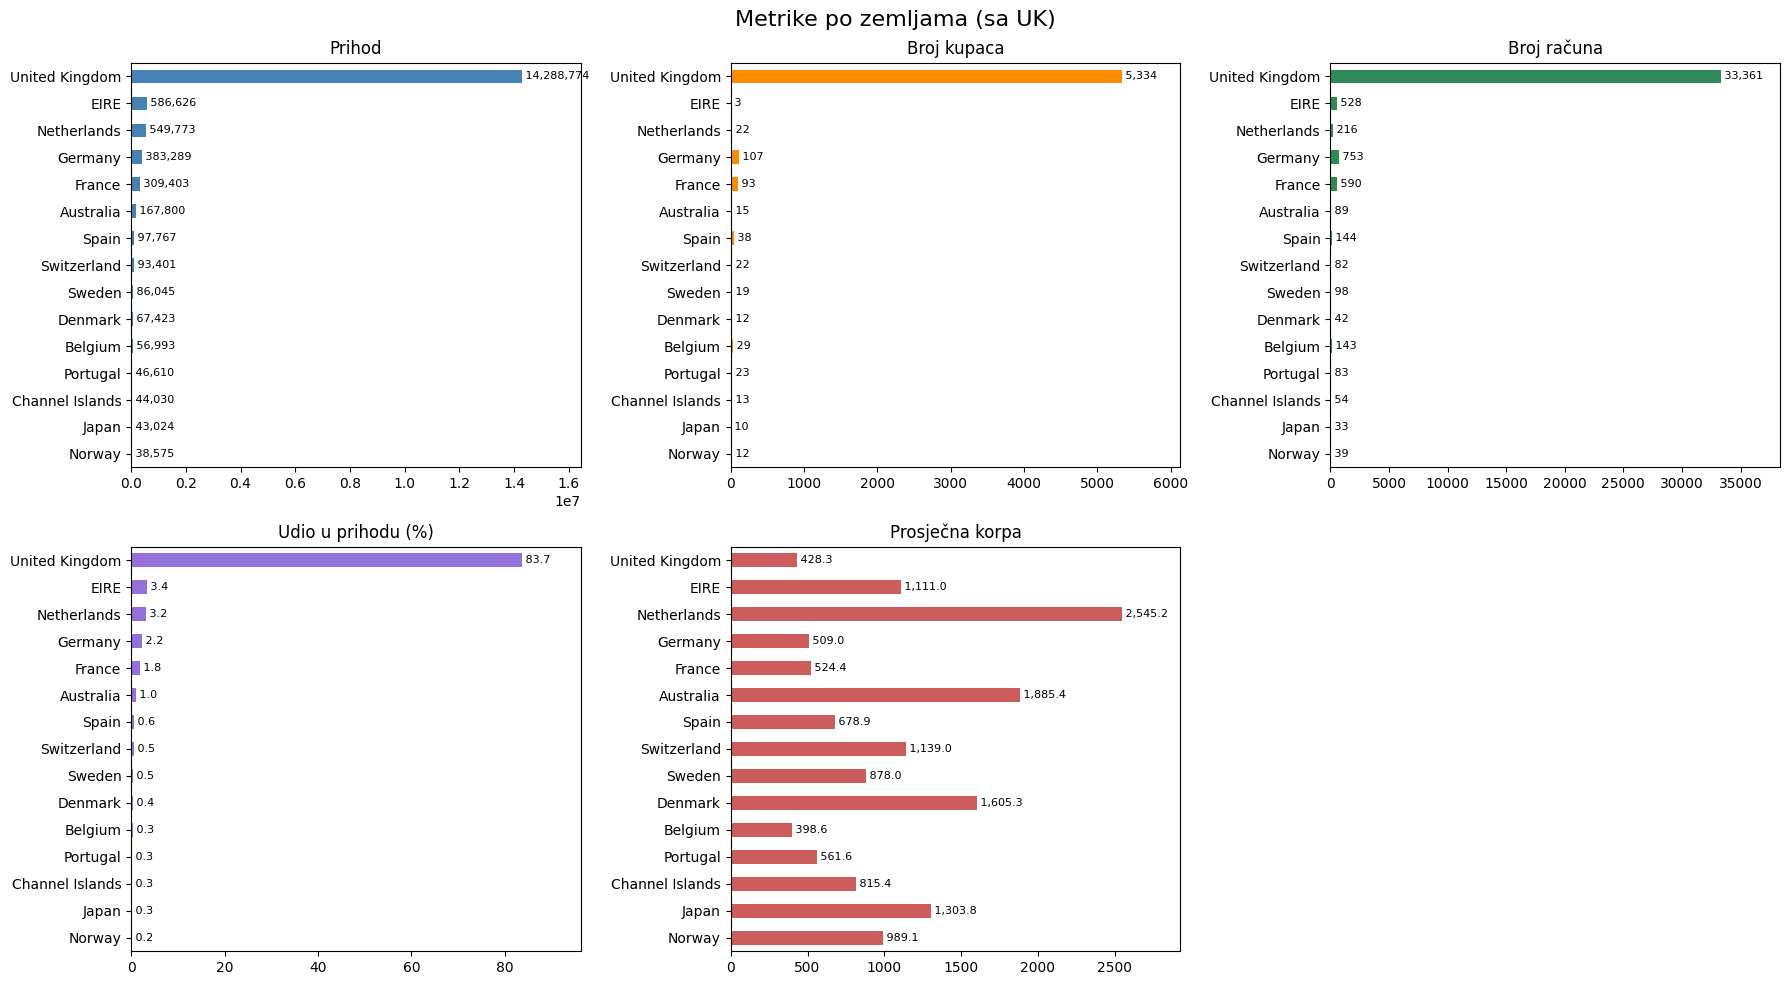

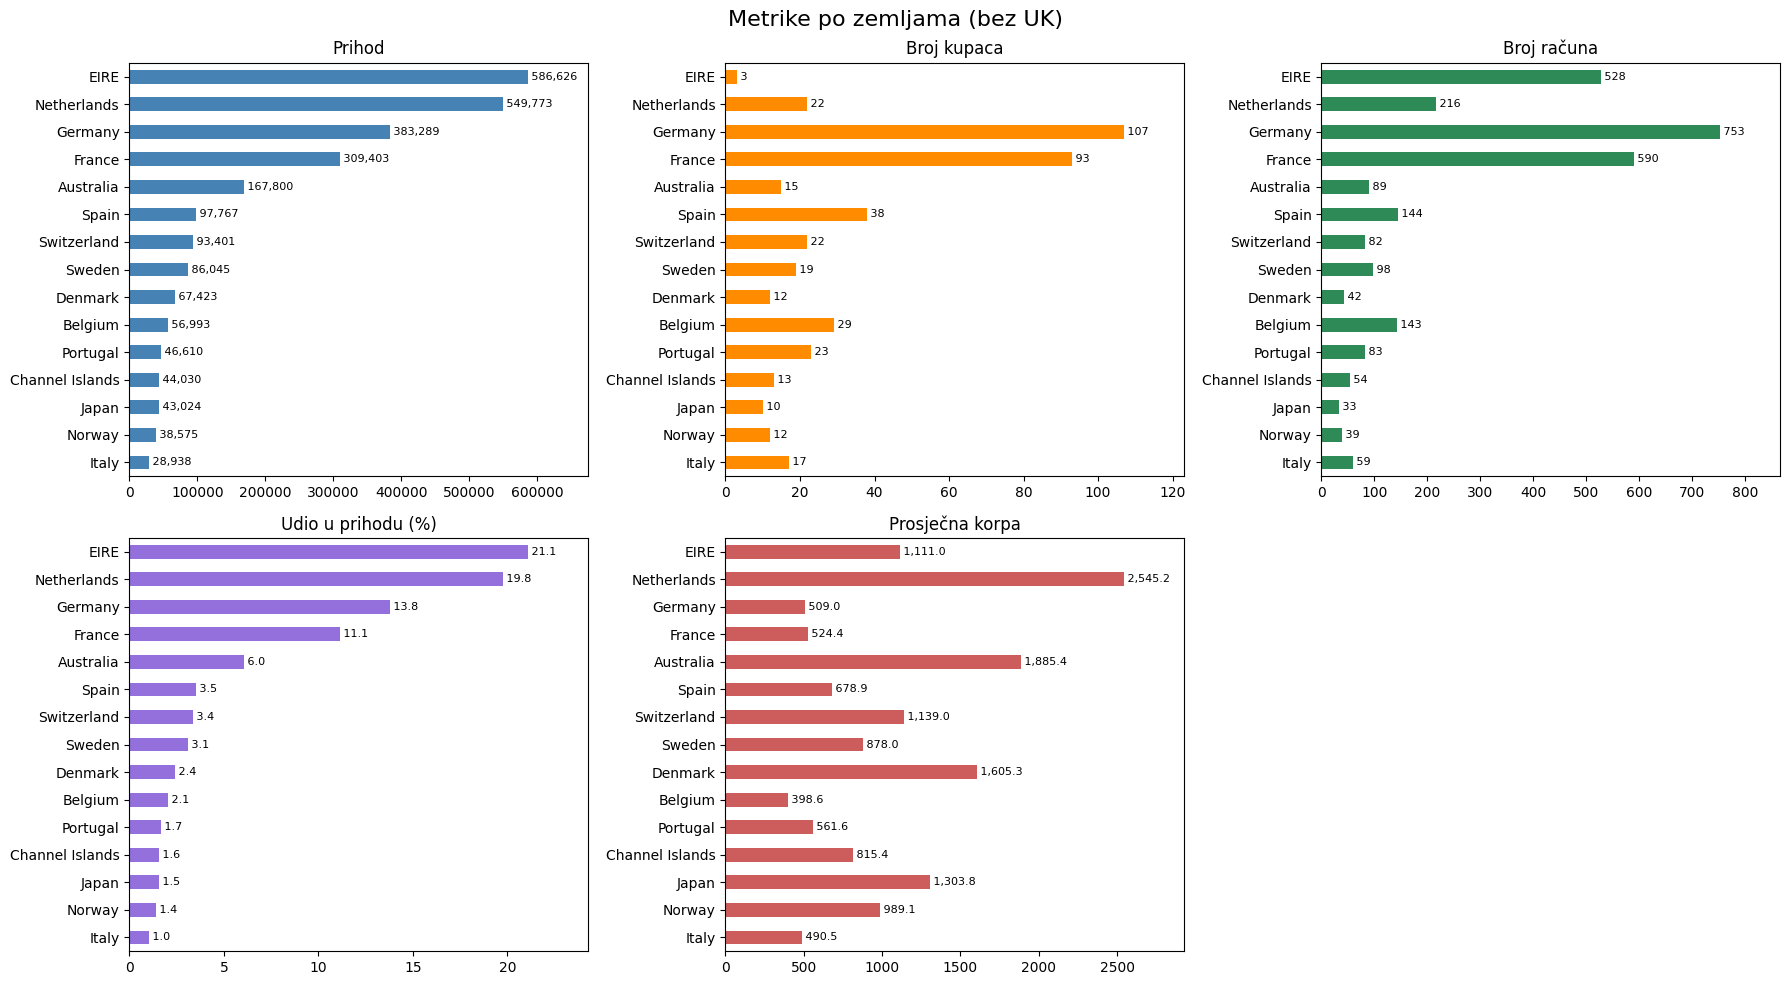

In [ ]:
def draw_by_countries(data, naslov, n=15):
    d = data.copy()
    d["Udeo %"] = d["Prihod"] / d["Prihod"].sum() * 100
    d = d.sort_values("Prihod", ascending=False).head(n)

    metrike = [
        ("Prihod", "steelblue", "Prihod"),
        ("Kupaca", "darkorange", "Broj kupaca"),
        ("Racuna", "seagreen", "Broj računa"),
        ("Udeo %", "mediumpurple", "Udio u prihodu (%)"),
        ("ProsecnaKorpa", "indianred", "Prosječna korpa"),
    ]

    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.ravel()

    for ax, (kol, boja, naz) in zip(axes, metrike):
        d[kol].plot(kind="barh", ax=ax, color=boja)
        ax.invert_yaxis()
        ax.set_title(naz)
        ax.set_ylabel("")
        for i, v in enumerate(d[kol]):
            ax.text(v, i, f" {v:,.1f}" if kol in ("Udeo %", "ProsecnaKorpa") else f" {v:,.0f}",
                    va="center", fontsize=8)
        ax.margins(x=0.15)

    axes[-1].axis("off") 
    fig.suptitle(naslov, fontsize=16)
    plt.tight_layout()
    plt.show()

draw_by_countries(by_countries, "Metrike po zemljama (sa UK)")

draw_by_countries(by_countries.drop("United Kingdom"), "Metrike po zemljama (bez UK)")